# Machine Learning Phase 6 - Classification and Clustering Project

**Project:** Bank Marketing - Term Deposit Subscription Prediction and Customer Segmentation  
**Prepared by:** Shraddha Yadav  
**Batch:** PGDA0226  
**Dataset:** UCI Bank Marketing (bank-additional-full.csv)

## Project objective
The project has two connected objectives. First, a classification model is built to predict whether a client will subscribe to a term deposit (`y`). Second, K-Means clustering is used without the target column to identify natural customer/campaign segments. The final section combines both results to show where the classifier performs well or poorly across the discovered segments.

**Important modelling decision:** `duration` is excluded from the predictive model because the UCI documentation states that call duration is only known after a call has taken place. Including it would create information leakage for a realistic pre-call targeting model.

## 1. Setup and data loading

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, silhouette_score)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

In [2]:
DATA_PATH = "bank-additional-full.csv"
df = pd.read_csv(DATA_PATH, sep=";")
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 2. Dataset justification and problem framing

The dataset contains direct-marketing campaign records from a Portuguese banking institution and includes client characteristics, contact details, previous campaign information, and five social/economic indicators. The full file contains 41,188 rows and 21 columns, meeting the project requirement for more than 1,000 rows and at least 8 usable features. The binary target `y` records whether the client subscribed to a term deposit.

**Business question:** Can the bank use information available before or at the time of campaign planning to identify clients more likely to subscribe, while also identifying meaningful customer/campaign segments?

**End user:** A bank marketing/campaign manager who decides which customer groups should receive attention and how campaign resources should be allocated.

## 3. Exploratory Data Analysis (EDA)

In [3]:
print("Column names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)

Column names:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']

Data types:
age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object


In [4]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


In [5]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean()*100).round(2)
})
unknown_rows = []
for col in df.select_dtypes(include="object").columns:
    if col != "y":
        unknown_rows.append([col, int((df[col] == "unknown").sum()), round((df[col] == "unknown").mean()*100, 2)])
unknown_summary = pd.DataFrame(unknown_rows, columns=["column","unknown_count","unknown_pct"])
print("Standard NaN missing values:")
display(missing[missing.missing_count > 0])
print("UCI-coded 'unknown' values:")
display(unknown_summary[unknown_summary.unknown_count > 0])
print("Exact duplicate rows:", df.duplicated().sum())

Standard NaN missing values:


,missing_count,missing_pct


UCI-coded 'unknown' values:


,column,unknown_count,unknown_pct
0,job,330,0.80
1,marital,80,0.19
2,education,1731,4.20
3,default,8597,20.87
4,housing,990,2.40
5,loan,990,2.40


Exact duplicate rows: 12


**EDA observation:** The file has no standard `NaN` values, but the source uses the text label `unknown` for missing/unspecified values in several categorical columns. These are retained as an explicit category rather than guessed or deleted, because `unknown` may itself carry information. Exact duplicate rows are removed before modelling.

     count  percentage
y                     
no   36548       88.73
yes   4640       11.27


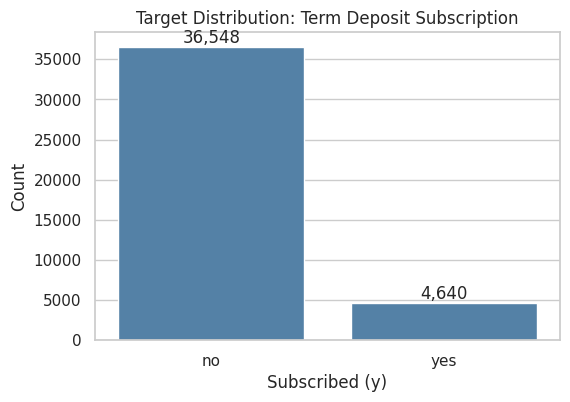

In [6]:
target_counts = df["y"].value_counts()
target_pct = (df["y"].value_counts(normalize=True)*100).round(2)
print(pd.DataFrame({"count": target_counts, "percentage": target_pct}))

plt.figure(figsize=(6,4))
ax = sns.countplot(data=df, x="y", color="steelblue")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.title("Target Distribution: Term Deposit Subscription")
plt.xlabel("Subscribed (y)")
plt.ylabel("Count")
plt.show()

**EDA observation:** The target is imbalanced: the majority class is `no`, while `yes` is a little over 11% of the data. This is still above the project guideline of roughly 10%, but accuracy alone would be misleading. Precision, recall and F1 for the positive (`yes`) class are therefore reported.

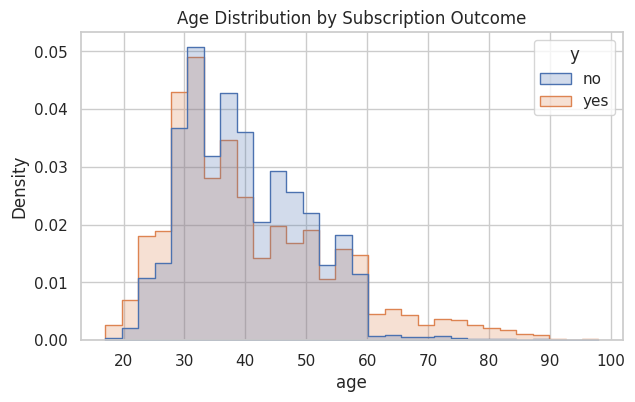

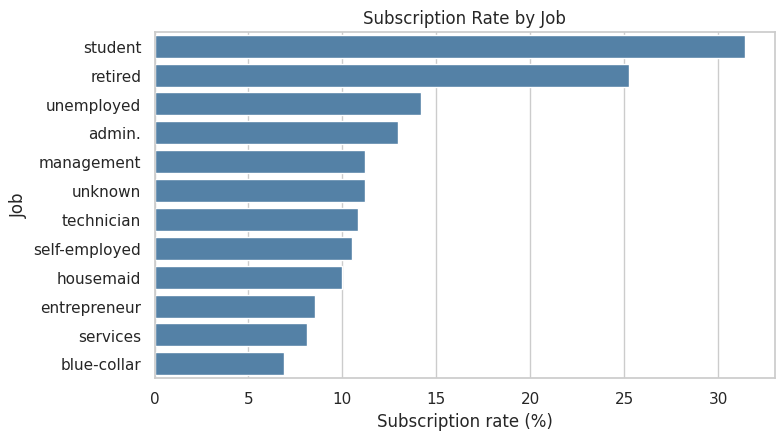

In [7]:
plt.figure(figsize=(7,4))
sns.histplot(data=df, x="age", hue="y", bins=30, element="step", stat="density", common_norm=False)
plt.title("Age Distribution by Subscription Outcome")
plt.show()

job_rates = df.groupby("job")["y"].apply(lambda s: (s=="yes").mean()).mul(100).sort_values(ascending=False)
plt.figure(figsize=(8,4.5))
sns.barplot(x=job_rates.values, y=job_rates.index, color="steelblue")
plt.title("Subscription Rate by Job")
plt.xlabel("Subscription rate (%)")
plt.ylabel("Job")
plt.show()

**EDA observation:** Subscription behaviour is not uniform across customer groups. Job categories show visibly different response rates, which supports retaining categorical client information in the classifier.

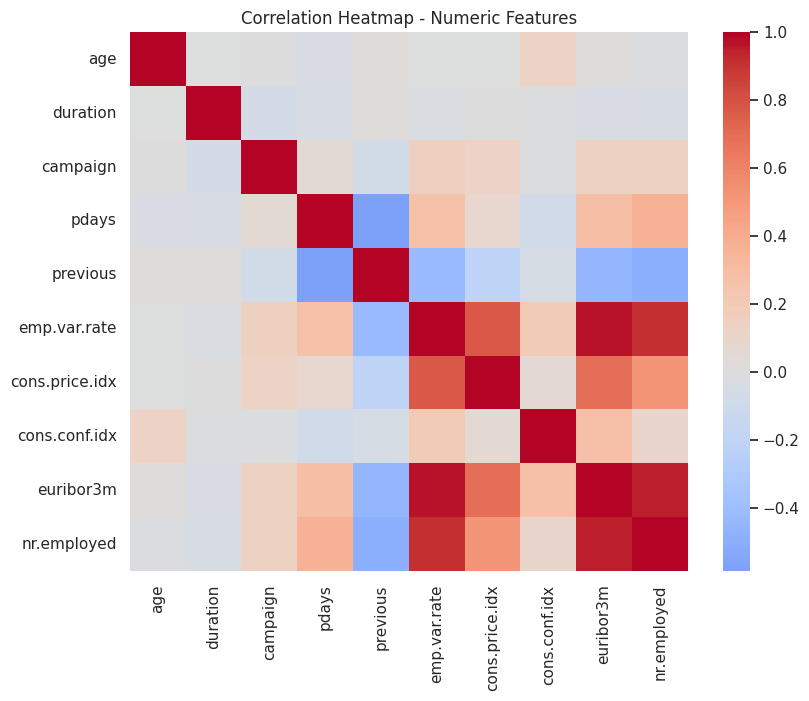

In [8]:
numeric_columns = df.select_dtypes(include=np.number).columns
plt.figure(figsize=(9,7))
sns.heatmap(df[numeric_columns].corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap - Numeric Features")
plt.show()

**EDA observation:** Several macroeconomic variables are strongly related to each other, especially `euribor3m`, `nr.employed`, and `emp.var.rate`. This is expected because they describe the same broad economic environment. The models are compared on the same split rather than removing these variables purely because of correlation.

## 4. Data preparation

Preparation choices:
- Remove exact duplicate rows.
- Keep `unknown` as a valid categorical level.
- Remove `duration` from the realistic predictive feature set to avoid post-call leakage.
- Use one-hot encoding for categorical features.
- Standardise numeric features inside the preprocessing pipeline.
- Use an 80/20 stratified train/test split with `random_state=42`.

In [9]:
model_df = df.drop_duplicates().reset_index(drop=True)
print("Rows before duplicate removal:", len(df))
print("Rows after duplicate removal:", len(model_df))

X = model_df.drop(columns=["y", "duration"])
y = (model_df["y"] == "yes").astype(int)

cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = X.select_dtypes(include=np.number).columns.tolist()
print("Numeric features:", num_cols)
print("Categorical features:", cat_cols)

Rows before duplicate removal: 41188
Rows after duplicate removal: 41176
Numeric features: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [10]:
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 32940
Test rows: 8236


## 5. Classification modelling

In [11]:
baseline_accuracy = max(y_test.mean(), 1-y_test.mean())
print(f"Majority-class baseline accuracy: {baseline_accuracy:.4f} ({baseline_accuracy*100:.2f}%)")

Majority-class baseline accuracy: 0.8873 (88.73%)


The baseline predicts every record as the majority class (`no`). Any useful model should be judged against this baseline, not against zero.

In [12]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
}

results = []
fitted_models = {}
predictions = {}

for name, estimator in models.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted_models[name] = pipe
    predictions[name] = pred
    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("F1", ascending=False).reset_index(drop=True)
display(results_df.style.format({"Accuracy":"{:.3f}","Precision":"{:.3f}","Recall":"{:.3f}","F1":"{:.3f}"}))

,Algorithm,Accuracy,Precision,Recall,F1
0,Random Forest,0.893,0.548,0.288,0.377
1,Decision Tree,0.841,0.316,0.353,0.334
2,Logistic Regression,0.898,0.650,0.210,0.318


**Model comparison interpretation:** Accuracy is high for all models because the target is dominated by the `no` class. F1 is used as the main comparison metric because it balances precision and recall for the positive class. Random Forest provides the strongest F1 among the three default-style models tested, so it is selected for detailed evaluation.

In [13]:
best_model_name = results_df.loc[0, "Algorithm"]
best_model = fitted_models[best_model_name]
y_pred = predictions[best_model_name]
print("Selected model:", best_model_name)
print(classification_report(y_test, y_pred, target_names=["No", "Yes"]))

Selected model: Random Forest
              precision    recall  f1-score   support

          No       0.91      0.97      0.94      7308
         Yes       0.55      0.29      0.38       928

    accuracy                           0.89      8236
   macro avg       0.73      0.63      0.66      8236
weighted avg       0.87      0.89      0.88      8236



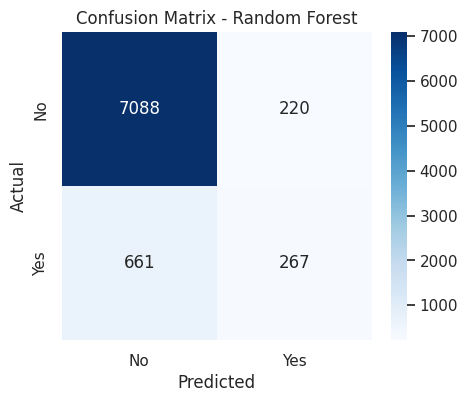

TN, FP, FN, TP = [7088  220  661  267]


In [14]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["No","Yes"], yticklabels=["No","Yes"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()
print("TN, FP, FN, TP =", cm.ravel())

**Confusion matrix interpretation:** The model is very strong at recognising non-subscribers, but it misses a substantial number of actual subscribers. For a campaign targeting problem, recall for `yes` is important because false negatives represent potentially receptive customers who would not be prioritised. The result shows why accuracy alone is not enough.

,feature,importance
0,num__age,0.158450
7,num__euribor3m,0.117169
1,num__campaign,0.080821
8,num__nr.employed,0.047640
2,num__pdays,0.029887
6,num__cons.conf.idx,0.027001
4,num__emp.var.rate,0.026838
61,cat__poutcome_success,0.026020
36,cat__housing_no,0.021133
38,cat__housing_yes,0.020727


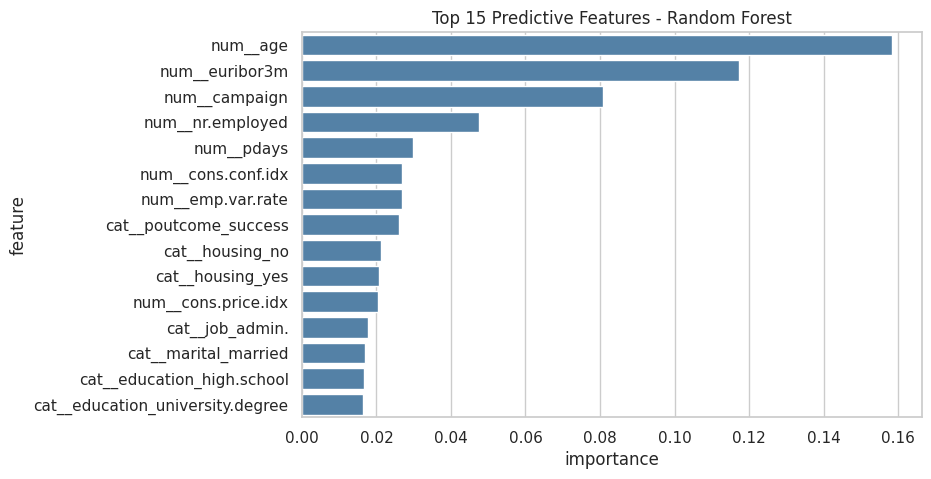

In [15]:
feature_names = best_model.named_steps["preprocess"].get_feature_names_out()
model_part = best_model.named_steps["model"]
if hasattr(model_part, "feature_importances_"):
    importance = model_part.feature_importances_
else:
    importance = np.abs(model_part.coef_[0])

feature_importance = (pd.DataFrame({"feature": feature_names, "importance": importance})
                      .sort_values("importance", ascending=False).head(15))
display(feature_importance)
plt.figure(figsize=(8,5))
sns.barplot(data=feature_importance, y="feature", x="importance", color="steelblue")
plt.title(f"Top 15 Predictive Features - {best_model_name}")
plt.show()

**Feature interpretation:** Age, macroeconomic conditions (especially `euribor3m`) and campaign/contact-history variables appear among the most influential predictors. The importance chart should be read as model influence rather than proof of causation.

## 6. Clustering model

The target `y` is removed completely from clustering. `duration` is also left out for consistency with the pre-call business use case. K-Means is applied to scaled numeric features because its distance calculations are sensitive to measurement scale.

In [16]:
cluster_features = [
    "age", "campaign", "pdays", "previous", "emp.var.rate",
    "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"
]
cluster_raw = model_df[cluster_features].copy()
cluster_scaler = StandardScaler()
Z = cluster_scaler.fit_transform(cluster_raw)
print("Clustering matrix shape:", Z.shape)

Clustering matrix shape: (41176, 9)


,k,inertia,silhouette
0,2,225686.087275,0.473716
1,3,175048.194395,0.488489
2,4,153158.250635,0.457489
3,5,132383.448972,0.469608
4,6,117574.981289,0.314825


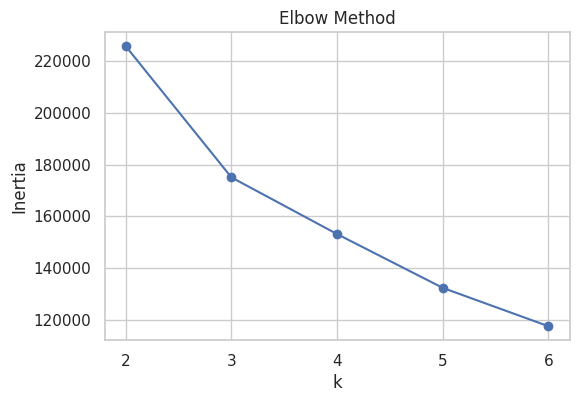

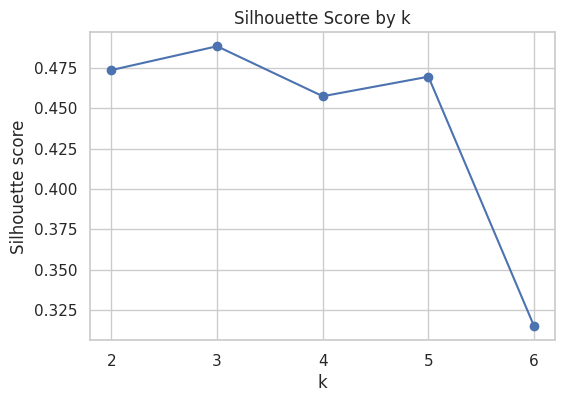

In [17]:
k_values = list(range(2,7))
inertias = []
silhouettes = []
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(len(Z), size=min(5000, len(Z)), replace=False)

for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(Z)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(Z[sample_idx], labels[sample_idx]))

k_table = pd.DataFrame({"k": k_values, "inertia": inertias, "silhouette": silhouettes})
display(k_table)

plt.figure(figsize=(6,4))
plt.plot(k_values, inertias, marker="o")
plt.xticks(k_values)
plt.xlabel("k")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

plt.figure(figsize=(6,4))
plt.plot(k_values, silhouettes, marker="o")
plt.xticks(k_values)
plt.xlabel("k")
plt.ylabel("Silhouette score")
plt.title("Silhouette Score by k")
plt.show()

**Choice of k:** `k=3` is selected because it has the highest silhouette score among the tested values and also provides a compact segmentation that can be interpreted by a marketing manager. This decision is based on both statistical separation and business usability.

In [18]:
chosen_k = int(k_table.loc[k_table["silhouette"].idxmax(), "k"])
kmeans = KMeans(n_clusters=chosen_k, random_state=RANDOM_STATE, n_init=10)
model_df["cluster"] = kmeans.fit_predict(Z)
print("Chosen k:", chosen_k)
print(model_df["cluster"].value_counts().sort_index())

Chosen k: 3
cluster
0    12001
1    27637
2     1538
Name: count, dtype: int64


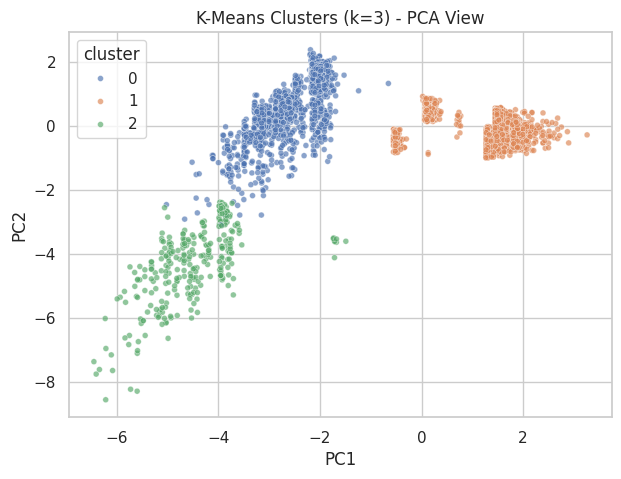

Variance explained by PC1 + PC2: 58.34 %


In [19]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pcs = pca.fit_transform(Z)
pca_df = pd.DataFrame({"PC1": pcs[:,0], "PC2": pcs[:,1], "cluster": model_df["cluster"].astype(str)})
plot_sample = pca_df.sample(min(8000, len(pca_df)), random_state=RANDOM_STATE)
plt.figure(figsize=(7,5))
sns.scatterplot(data=plot_sample, x="PC1", y="PC2", hue="cluster", s=18, alpha=0.65)
plt.title(f"K-Means Clusters (k={chosen_k}) - PCA View")
plt.show()
print("Variance explained by PC1 + PC2:", round(pca.explained_variance_ratio_.sum()*100,2), "%")

In [20]:
cluster_profile = model_df.groupby("cluster")[cluster_features].mean().round(2)
cluster_profile["size"] = model_df.groupby("cluster").size()
cluster_profile["size_pct"] = (cluster_profile["size"] / len(model_df) * 100).round(2)
cluster_profile["subscription_rate_pct"] = (model_df.groupby("cluster")["y"].apply(lambda s: (s=="yes").mean())*100).round(2)

segment_names = {
    0: "Mainstream Low-Engagement Segment",
    1: "High-Contact Campaign Segment",
    2: "Previously Engaged - Higher Response"
}
cluster_profile.insert(0, "segment_name", [segment_names[i] for i in cluster_profile.index])
display(cluster_profile)

,segment_name,age,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,size,size_pct,subscription_rate_pct
cluster,,,,,,,,,,,,,
0,Mainstream Low-Engagement Segment,39.39,2.13,999.00,0.32,-2.03,92.99,-43.19,1.20,5077.96,12001,29.15,19.44
1,High-Contact Campaign Segment,40.19,2.80,999.00,0.03,1.12,93.84,-39.46,4.82,5213.42,27637,67.12,4.83
2,Previously Engaged - Higher Response,41.94,1.83,20.86,1.69,-2.09,93.35,-38.33,0.98,5028.63,1538,3.74,63.13


### Cluster profiles

- **Cluster 0 - Mainstream Low-Engagement Segment:** A sizeable group operating mainly in a lower-rate environment, with limited previous-contact history and a moderate response rate relative to the largest cluster.
- **Cluster 1 - High-Contact Campaign Segment:** The largest group. It has more current-campaign contacts, almost no previous-contact history and the lowest subscription rate. Repeated contact does not automatically translate into conversion.
- **Cluster 2 - Previously Engaged - Higher Response:** A small but highly distinctive segment with strong previous-contact history, low `pdays`, and by far the highest observed subscription rate. This is the most responsive natural segment.

## 7. Integration of classification and clustering

In [21]:
cluster_vs_target = pd.crosstab(model_df["cluster"], model_df["y"], normalize="index").mul(100).round(2)
cluster_vs_target.index = [f"{i} - {segment_names[i]}" for i in cluster_vs_target.index]
display(cluster_vs_target)

y,no,yes
0 - Mainstream Low-Engagement Segment,80.56,19.44
1 - High-Contact Campaign Segment,95.17,4.83
2 - Previously Engaged - Higher Response,36.87,63.13


**Integration finding 1:** The natural clusters are strongly related to the real outcome even though the target was not used to create them. In particular, the previously engaged cluster has a much higher `yes` rate, whereas the high-contact cluster has a very low rate. This suggests that campaign history and economic context contain meaningful structure connected to propensity.

In [22]:
test_clusters = model_df.loc[X_test.index, "cluster"]
rows = []
for c in sorted(test_clusters.unique()):
    mask = (test_clusters == c).values
    yt = y_test.iloc[np.where(mask)[0]]
    yp = y_pred[mask]
    rows.append({
        "cluster": int(c),
        "segment_name": segment_names[int(c)],
        "test_n": int(mask.sum()),
        "accuracy": accuracy_score(yt, yp),
        "recall_yes": recall_score(yt, yp, zero_division=0),
        "f1_yes": f1_score(yt, yp, zero_division=0)
    })
accuracy_by_cluster = pd.DataFrame(rows)
display(accuracy_by_cluster.style.format({"accuracy":"{:.3f}","recall_yes":"{:.3f}","f1_yes":"{:.3f}"}))

,cluster,segment_name,test_n,accuracy,recall_yes,f1_yes
0,0,Mainstream Low-Engagement Segment,2374,0.789,0.220,0.302
1,1,High-Contact Campaign Segment,5548,0.951,0.036,0.062
2,2,Previously Engaged - Higher Response,314,0.659,0.798,0.737


**Integration finding 2:** Overall accuracy is highest in the large low-response cluster, largely because most observations there are `no`. By contrast, positive-class recall and F1 are much stronger in the previously engaged/high-response segment. The classifier is therefore not equally useful across all customer segments.

**Actionable conclusion:** The bank should not interpret the model's overall accuracy as uniform performance. Previously engaged customers form a small but high-propensity segment and deserve focused attention, while the high-contact/low-response segment may require tighter contact policies to avoid inefficient repeated outreach. Model evaluation should be monitored by segment, especially positive-class recall, rather than relying on a single overall accuracy figure.

## 8. Final conclusion

This project combined supervised classification with unsupervised clustering on the same Bank Marketing dataset. The realistic classifier excluded call duration to avoid information leakage. Random Forest produced the strongest F1 score among the compared models, although positive-class recall remained modest because the target is imbalanced and default model settings were intentionally used. K-Means identified three interpretable segments, including a small previously engaged segment with a very high subscription rate. The integrated analysis showed that model performance varies materially by segment, giving a campaign manager more useful information than a single accuracy score alone.

## 9. Reproducibility

All random operations use `random_state=42`. The notebook is designed to run from top to bottom with `bank-additional-full.csv` stored in the same folder.